# CSE558 Midterm: Wine Reviews. Is a score a property of the wine or of the critic?

Statistical inference through hypothesis testing on WineEnthusiast reviews
(Kaggle `zynicide/wine-reviews`, file **`winemag-data-130k-v2.csv` only**).

Run top to bottom (*Kernel → Restart & Run All*). Every number in the report comes from this notebook.
Section 7 writes `report/numbers.tex` (used in LaTeX as `\val{key}`), `report/tables/*.tex` and `figures/*.pdf`.

| Notebook section | Report section |
|---|---|
| 0 Setup and helpers | |
| 1 Dataset | 1 Dataset |
| 2 Data preparation (incl. encoding and the 3M size check) | 1 (size check), 2 Data preparation |
| 3 Before and after | 3 What changed after preparation |
| 4 EDA, basic questions, problem statements | 4 Basic questions and problem statement |
| 5 Hypothesis tests T1–T5 | 5 Statistical inferences |
| 6 Limitations | 6 Limitations |
| 7 Export | |

Only methods from the lectures are used (L2–L8): descriptive statistics, boxplots, quantile and Q-Q plots,
Pearson correlation, z/t tests, F and chi-square tests.

## 0. Setup and helpers

In [1]:
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

SEED = 558
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data' / 'winemag-data-130k-v2.csv'
FIG = ROOT / 'figures'
TAB = ROOT / 'report' / 'tables'
FIG.mkdir(exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 60)

# Chart style: one blue for a single series, blue/orange for a two-group comparison, recessive grey axes.
BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3de'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 8, 'axes.titlesize': 8.5,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK2,
    'axes.labelcolor': INK, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.prop_cycle': cycler(color=[BLUE, ORANGE]), 'lines.linewidth': 1.5, 'legend.frameon': False,
})

In [2]:
NUM = {}       # key -> LaTeX text, written to report/numbers.tex; the report uses \val{key}
SUMMARY = []   # one row per hypothesis test, for the summary table


class Tex(str):
    """A table cell that is already LaTeX and must not be escaped."""


def tex_escape(s):
    """Escape the LaTeX specials that occur in our labels."""
    return re.sub(r'([&%$#_])', r'\\\1', str(s))


def num(x, d=2):
    """Fixed-point number for LaTeX with a real minus sign."""
    s = f'{abs(x):,.{d}f}'
    return Tex(rf'\ensuremath{{-{s}}}' if x < 0 and float(s.replace(',', '')) != 0 else s)


def tex_p(p):
    """p-value for LaTeX: 0.023, 4.4 x 10^-7, or <10^-300 once it underflows."""
    if p == 0:
        return Tex(r'\ensuremath{<10^{-300}}')
    if p >= 0.001:
        return Tex(f'{p:.3f}')
    m, e = f'{p:.1e}'.split('e')
    return Tex(rf'\ensuremath{{{m}\times10^{{{int(e)}}}}}')


def keep(key, value, fmt='{:,}'):
    """Store a value for the report, where it is printed by val{key}."""
    assert re.fullmatch(r'[A-Za-z0-9]+', key), key
    NUM[key] = fmt(value) if callable(fmt) else fmt.format(value)


def takeaway(key, text):
    """One-line figure caption: printed here and stored for the report."""
    print('Takeaway:', text)
    NUM[key] = tex_escape(text)


def save_table(df, name, index=False):
    """Write a booktabs tabular to report/tables/<name>.tex."""
    if index:
        df = df.reset_index()
    cell = lambda v: v if isinstance(v, Tex) else tex_escape(v)
    lines = [rf'\begin{{tabular}}{{{"l" * df.shape[1]}}}', r'\toprule',
             ' & '.join(rf'\textbf{{{tex_escape(c)}}}' for c in df.columns) + r' \\', r'\midrule']
    lines += [' & '.join(cell(v) for v in row) + r' \\' for row in df.itertuples(index=False)]
    lines += [r'\bottomrule', r'\end{tabular}']
    (TAB / f'{name}.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')


def save_fig(fig, name):
    fig.savefig(FIG / f'{name}.pdf')
    plt.show()


def pearson_skew(x):
    """Karl Pearson's second skewness coefficient, 3(mean - median)/SD."""
    return 3 * (x.mean() - x.median()) / x.std()

In [3]:
Z975 = stats.norm.ppf(0.975)


def p_value(dist, stat, side):
    """p-value of a z or t statistic for the side of H1: 'two-sided', 'less' or 'greater'."""
    if side == 'two-sided':
        return 2 * dist.sf(abs(stat))
    return dist.cdf(stat) if side == 'less' else dist.sf(stat)


def welch_t(x, y, side='two-sided'):
    """Unpooled two-sample t: SE = sqrt(s1^2/n1 + s2^2/n2), Welch-Satterthwaite df."""
    n1, n2 = len(x), len(y)
    v1, v2 = x.var(ddof=1) / n1, y.var(ddof=1) / n2
    est, se = x.mean() - y.mean(), np.sqrt(v1 + v2)
    df = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))
    m = stats.t.ppf(0.975, df) * se
    return dict(test='Welch t', stat=est / se, df=df, p=p_value(stats.t(df), est / se, side),
                est=est, lo=est - m, hi=est + m)


def pooled_t(x, y, side='two-sided'):
    """Pooled two-sample t: one common variance, df = n1 + n2 - 2."""
    n1, n2 = len(x), len(y)
    sp2 = ((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / (n1 + n2 - 2)
    est, se, df = x.mean() - y.mean(), np.sqrt(sp2 * (1 / n1 + 1 / n2)), n1 + n2 - 2
    m = stats.t.ppf(0.975, df) * se
    return dict(test='pooled t', stat=est / se, df=df, p=p_value(stats.t(df), est / se, side),
                est=est, lo=est - m, hi=est + m)


def z_two_means(x, y, side='two-sided'):
    """Large-sample z for two means; the sample SDs stand in for the unknown sigmas."""
    est = x.mean() - y.mean()
    se = np.sqrt(x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y))
    return dict(test='two-sample z', stat=est / se, df=None, p=p_value(stats.norm, est / se, side),
                est=est, lo=est - Z975 * se, hi=est + Z975 * se)


def f_test(x, y):
    """F = s1^2/s2^2 with (n1-1, n2-1) df, two-sided; the CI is for the variance ratio."""
    F, d1, d2 = x.var(ddof=1) / y.var(ddof=1), len(x) - 1, len(y) - 1
    p = 2 * min(stats.f.cdf(F, d1, d2), stats.f.sf(F, d1, d2))
    return dict(test='F', stat=F, df=(d1, d2), p=p, est=F,
                lo=F / stats.f.ppf(0.975, d1, d2), hi=F / stats.f.ppf(0.025, d1, d2))


def r_test(x, y, side='two-sided'):
    """t = r sqrt(n-2) / sqrt(1-r^2) with n-2 df; the CI for rho uses Fisher's z = atanh(r)."""
    n, r = len(x), np.corrcoef(x, y)[0, 1]
    t = r * np.sqrt((n - 2) / (1 - r ** 2))
    h = Z975 / np.sqrt(n - 3)
    return dict(test='t on Pearson r', stat=t, df=n - 2, p=p_value(stats.t(n - 2), t, side),
                est=r, lo=np.tanh(np.arctanh(r) - h), hi=np.tanh(np.arctanh(r) + h))


def z_two_props(k1, n1, k2, n2, side='two-sided'):
    """z for p1 - p2 with the pooled rate under H0; the CI uses the unpooled SE."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return dict(test='two-proportion z', stat=z, df=None, p=p_value(stats.norm, z, side),
                est=p1 - p2, lo=p1 - p2 - Z975 * se, hi=p1 - p2 + Z975 * se)


def chi2_variance(x, var0):
    """One-sample chi-square for a variance, (n-1)s^2/sigma0^2 with n-1 df, two-sided."""
    n, s2 = len(x), x.var(ddof=1)
    c = (n - 1) * s2 / var0
    p = 2 * min(stats.chi2.cdf(c, n - 1), stats.chi2.sf(c, n - 1))
    return dict(test='chi-square for a variance', stat=c, df=n - 1, p=p, est=s2,
                lo=(n - 1) * s2 / stats.chi2.ppf(0.975, n - 1), hi=(n - 1) * s2 / stats.chi2.ppf(0.025, n - 1))


def decide(p):
    return 'reject H0' if p < ALPHA else 'fail to reject H0'


def df_text(df):
    if df is None:
        return '-'
    if isinstance(df, tuple):
        return f'{df[0]:,}, {df[1]:,}'
    return f'{df:,.0f}'


def show(res):
    print(f"{res['test']}: statistic = {res['stat']:.3f}, df = {df_text(res['df'])}, "
          f"p = {res['p']:.3g} -> {decide(res['p'])}; estimate = {res['est']:.4f}, "
          f"95% CI [{res['lo']:.4f}, {res['hi']:.4f}]")


def matters(lo, hi, delta):
    """Read the 95% CI against the smallest effect that matters, |effect| >= delta."""
    if lo >= delta or hi <= -delta:
        return 'matters'
    if -delta < lo and hi < delta:
        return 'does not matter'
    return 'unclear'


def keep_test(key, res, d=2, scale=1):
    """Store statistic, df, p, decision, estimate and CI under <key>Stat, <key>Df, <key>P, ..."""
    keep(key + 'Stat', res['stat'], lambda v: num(v, 2))
    keep(key + 'Df', res['df'], df_text)
    keep(key + 'P', res['p'], tex_p)
    keep(key + 'Decision', decide(res['p']), lambda s: s.replace('H0', r'\ensuremath{H_0}'))
    for part in ('est', 'lo', 'hi'):
        keep(key + part.capitalize(), res[part] * scale, lambda v: num(v, d))

## 1. Dataset

**Source:** Kaggle, *Wine Reviews* by zynicide (https://www.kaggle.com/datasets/zynicide/wine-reviews),
scraped from WineEnthusiast in 2017. One row is one published review of one wine.
We use only `winemag-data-130k-v2.csv` (the newer scrape, which adds `title` and the taster columns);
`winemag-data_first150k.csv` is not used.

In [4]:
raw = pd.read_csv(DATA, index_col=0)   # the first column is a saved pandas index, not an attribute
keep('rowsRaw', raw.shape[0])
keep('colsRaw', raw.shape[1])
keep('cellsRaw', raw.size)
print(f'{raw.shape[0]:,} rows x {raw.shape[1]} attributes = {raw.size:,} cells')
raw.head(3)

129,971 rows x 13 attributes = 1,689,623 cells


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimstone and drie...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth while sti...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and rind domi...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm


In [5]:
FEATURES = {
    'points':      ('discrete', 'WineEnthusiast score; 80-100 published only; our response'),
    'price':       ('continuous', 'bottle price in US dollars'),
    'country':     ('nominal', 'country the wine is from'),
    'province':    ('nominal', 'state or province, e.g. Washington, Bordeaux'),
    'region_1':    ('nominal', 'wine-growing area inside the province'),
    'region_2':    ('nominal', 'wider area (US only)'),
    'variety':     ('nominal', 'grape variety or blend'),
    'winery':      ('nominal', 'producer'),
    'designation': ('nominal', 'vineyard or cuvee name on the label'),
    'title':       ('text', 'wine name; carries the vintage year'),
    'description': ('text', "the critic's tasting note"),
    'taster_name': ('nominal', 'critic who tasted and scored the wine'),
    'taster_twitter_handle': ('nominal', "critic's Twitter handle"),
}
feat = pd.DataFrame({
    'type': {c: t for c, (t, _) in FEATURES.items()},
    'levels': raw.nunique(),
    'missing %': (raw.isna().mean() * 100).round(1),
    'meaning': {c: m for c, (_, m) in FEATURES.items()},
}).loc[list(FEATURES)]
key_features = ['points', 'price', 'country', 'province', 'variety', 'taster_name', 'title', 'description']
save_table(feat.loc[key_features, ['type', 'meaning']].rename_axis('feature'), 'features', index=True)
feat

,type,levels,missing %,meaning
points,discrete,21,0.0,WineEnthusiast score; 80-100 published only; our response
price,continuous,390,6.9,bottle price in US dollars
country,nominal,43,0.0,country the wine is from
province,nominal,425,0.0,"state or province, e.g. Washington, Bordeaux"
region_1,nominal,1229,16.3,wine-growing area inside the province
region_2,nominal,17,61.1,wider area (US only)
variety,nominal,707,0.0,grape variety or blend
winery,nominal,16757,0.0,producer
designation,nominal,37979,28.8,vineyard or cuvee name on the label
title,text,118840,0.0,wine name; carries the vintage year


The size check (instances × attributes ≥ 3,000,000 after encoding) is computed at the end of Section 2,
once the encoded table exists.

## 2. Data preparation

Each step logs the row and column count; the log becomes the before/after table of Section 3.
Every step is written as *issue → what we did → why, and not the alternative*.

In [6]:
log = []


def log_step(d, step, note=''):
    log.append({'step': step, 'rows': len(d), 'cols': d.shape[1], 'note': note})
    print(f'{step:<38} {len(d):>8,} rows x {d.shape[1]:>2} cols   {note}')


log_step(raw, '0 raw file')

0 raw file                              129,971 rows x 13 cols   


### 2.1 Exact duplicates
**Issue:** whole rows repeated. **What:** drop them. **Why:** the same review scraped twice is one
observation; keeping both inflates *n* and shrinks every standard error.

In [7]:
n_dup = raw.duplicated().sum()
assert n_dup == 9983
keep('nDup', n_dup)
df = raw.drop_duplicates().reset_index(drop=True)
log_step(df, '1 drop exact duplicates', f'-{n_dup:,}')

1 drop exact duplicates                 119,988 rows x 13 cols   -9,983


### 2.2 Descriptions shared by two rows (near-duplicates)
**Issue:** some tasting notes appear on two different rows. **What:** inspect them, then keep the first row of
each pair. **Why:** the output below shows the titles always differ and the scores often do, so the same
note was pasted onto two wines (for example, two barrel samples tasted together). One copy keeps the wine
but stops the text counting twice in the description-length test (T2).

In [8]:
shared = df[df.description.duplicated(keep=False)].sort_values('description')
n_pairs = shared.description.nunique()
print(f'{n_pairs} texts, group sizes: {shared.groupby("description").size().unique()}')
differs = shared.groupby('description')[[c for c in df.columns if c != 'description']].nunique().gt(1).sum()
print('Pairs in which each column differs:')
print(differs[differs > 0].to_string())
keep('nNearPairs', n_pairs)
keep('nNearPointsDiffer', differs['points'])
shared[['title', 'points', 'price', 'taster_name']].head(6)

33 texts, group sizes: [2]
Pairs in which each column differs:
country                   1
designation              11
points                   23
price                    20
province                  3
region_1                  8
region_2                  1
taster_name               1
taster_twitter_handle     1
title                    33
variety                  10
winery                   21


,title,points,price,taster_name
68590,Château Maucaillou 2012 Barrel Sample (Moulis-en-Médoc),91,NaN,Roger Voss
68588,Château Pontac-Lynch 2012 Barrel Sample (Margaux),91,NaN,Roger Voss
98994,Château Gruaud Larose 2012 Barrel Sample (Saint-Julien),93,NaN,Roger Voss
98989,Château Grand-Puy-Lacoste 2012 Barrel Sample (Pauillac),93,NaN,Roger Voss
70436,Stefano Accordini 2007 Passo Red (Rosso del Veronese),88,35.0,NaN
70421,Stefano Accordini 2008 Passo Red (Rosso del Veronese),88,35.0,NaN


In [9]:
n_near = df.description.duplicated().sum()
df = df[~df.description.duplicated(keep='first')].reset_index(drop=True)
keep('nNear', n_near)
log_step(df, '2 drop shared descriptions', f'-{n_near}')

2 drop shared descriptions              119,955 rows x 13 cols   -33


### 2.3 Rows missing `country` or `variety`
**Issue:** a handful of rows have no country (and one has no variety). **What:** drop them. **Why:** the
tests group wines by country and variety, so these rows cannot be used. Guessing a country would invent data,
and there are too few rows to bias anything.

In [10]:
miss_cv = df.country.isna() | df.variety.isna()
print(df.loc[miss_cv, ['country', 'province', 'variety']].isna().sum().to_string())
n_cv = miss_cv.sum()
keep('nMissCV', n_cv)
df = df[~miss_cv].reset_index(drop=True)
log_step(df, '3 drop missing country/variety', f'-{n_cv}')

country     59
province    59
variety      1
3 drop missing country/variety          119,895 rows x 13 cols   -60


### 2.4 Missing `price`: random or systematic?
Before choosing a fix we check whether missingness depends on country, using a chi-square test for
independence on *country (top 9 + Other) × price missing*. If it is systematic, a global fill would be biased.

In [11]:
df['price_imputed'] = df.price.isna()
top9 = df.country.value_counts().index[:9]
country9 = df.country.where(df.country.isin(top9), 'Other')

miss_by_country = df.groupby(country9).price_imputed.agg(rate='mean', n='size').sort_values('rate', ascending=False)
print(miss_by_country.round(3).to_string())
obs = pd.crosstab(country9, df.price_imputed)
chi2_miss, p_miss, dof_miss, _ = stats.chi2_contingency(obs, correction=False)
print(f'\nchi-square = {chi2_miss:,.1f}, df = {dof_miss}, p = {p_miss:.3g} -> {decide(p_miss)}')
print('\nMissing-price rate by taster:')
print(df.groupby(df.taster_name.fillna('(none)')).price_imputed.mean().sort_values(ascending=False).head(6).round(3).to_string())

keep('nPriceMiss', df.price_imputed.sum())
keep('pctPriceMiss', 100 * df.price_imputed.mean(), '{:.1f}')
keep('chiMiss', chi2_miss, '{:,.0f}')
keep('dfMiss', dof_miss)
keep('pMiss', p_miss, tex_p)
keep('missTopCountry', miss_by_country.index[0], '{}')
keep('missTopRate', 100 * miss_by_country.rate.iloc[0], '{:.1f}')

            rate      n
country                
France     0.200  20351
Austria    0.164   3033
Portugal   0.143   5256
Italy      0.136  17921
Other      0.033   6847
Chile      0.013   4183
Australia  0.013   2197
Argentina  0.012   3543
Spain      0.011   6116
US         0.004  50448

chi-square = 11,618.3, df = 9, p = 0 -> reject H0

Missing-price rate by taster:
taster_name
Roger Voss          0.213
Kerin O’Keefe       0.083
Anne Krebiehl MW    0.077
Lauren Buzzeo       0.068
(none)              0.066
Joe Czerwinski      0.026


Missingness is **systematic** (it depends strongly on country), so: **what:** fill each missing price with the
**median price of the same country** and keep a `price_imputed` flag; **imputed rows are left out of every test**.
**Why the median:** price is right-skewed, so the mean would be pulled up by luxury bottles. **Why not delete:**
the rows still carry a real score, country and variety, and deleting them would take the encoded table below
3M cells (shown in 2.12).

In [12]:
country_median = df.groupby('country').price.transform('median')
df['price'] = df.price.fillna(country_median).fillna(df.price.median())  # last fill: a country with no prices at all
n_global_fill = country_median.isna().sum()
print(f'filled {df.price_imputed.sum():,} prices; {n_global_fill} needed the global median (country had no prices)')
assert df.price.notna().all()
log_step(df, '4 impute price (country median)', f'+price_imputed flag')

filled 8,384 prices; 1 needed the global median (country had no prices)
4 impute price (country median)         119,895 rows x 14 cols   +price_imputed flag


### 2.5 Missing `taster_name`
**Issue:** about 1 in 5 reviews has no taster. **What:** fill with `"Unknown"`. **Why:** the review and score
exist, and missingness is systematic (rates below). Dropping the rows would remove a large share of some countries'
reviews and bias every country comparison. The taster tests (T4, T5) select named critics, so `"Unknown"` never
enters them.

In [13]:
t_missing = df.taster_name.isna()
rate_t = t_missing.groupby(country9).mean().sort_values(ascending=False)
print(rate_t.round(3).to_string())
chi2_t, p_t, dof_t, _ = stats.chi2_contingency(pd.crosstab(country9, t_missing), correction=False)
print(f'\nchi-square = {chi2_t:,.1f}, df = {dof_t}, p = {p_t:.3g} -> systematic: {p_t < ALPHA}')
keep('nTasterMiss', t_missing.sum())
keep('pctTasterMiss', 100 * t_missing.mean(), '{:.1f}')
keep('tasterMissTopCountry', rate_t.index[0], '{}')
keep('tasterMissTopRate', 100 * rate_t.iloc[0], '{:.1f}')
df['taster_name'] = df.taster_name.fillna('Unknown')
log_step(df, '5 taster_name -> "Unknown"')

country
Italy        0.445
US           0.317
Australia    0.131
Other        0.031
Chile        0.026
France       0.013
Spain        0.010
Austria      0.003
Portugal     0.001
Argentina    0.001

chi-square = 21,220.5, df = 9, p = 0 -> systematic: True
5 taster_name -> "Unknown"              119,895 rows x 14 cols   


### 2.6 Columns dropped

In [14]:
handles_per_taster = df.groupby('taster_name').taster_twitter_handle.nunique().max()
region2_countries = df.loc[df.region_2.notna(), 'country'].unique()
print('countries with region_2:', region2_countries, '| max Twitter handles per taster:', handles_per_taster)

DROP = {
    'region_2': f'{df.region_2.isna().mean():.0%} missing and only filled for {", ".join(region2_countries)}',
    'taster_twitter_handle': f'at most {handles_per_taster} handle per taster, so it repeats taster_name',
    'winery': f'{df.winery.nunique():,} levels: an ID, not a group we can compare',
    'designation': f'{df.designation.nunique():,} levels and {df.designation.isna().mean():.0%} missing',
}
for c, why in DROP.items():
    print(f'{c:<22} {why}')
keep('wineryLevels', df.winery.nunique())
keep('designationLevels', df.designation.nunique())
keep('pctRegionTwoMiss', 100 * df.region_2.isna().mean(), '{:.0f}')
winery_col = df.winery.copy()   # kept for the independence check in Section 6
df = df.drop(columns=list(DROP))
log_step(df, '6 drop 4 columns', ', '.join(DROP))

countries with region_2: ['US'] | max Twitter handles per taster: 1


region_2               61% missing and only filled for US
taster_twitter_handle  at most 1 handle per taster, so it repeats taster_name
winery                 16,743 levels: an ID, not a group we can compare
designation            37,950 levels and 29% missing
6 drop 4 columns                        119,895 rows x 10 cols   region_2, taster_twitter_handle, winery, designation


### 2.7 String junk
**Issue:** double spaces in titles and a non-breaking space (`\xa0`) inside some taster names.
**What:** replace `\xa0` with a space and collapse runs of spaces in every text column.
**Why:** an exact-match filter such as `taster_name == "Anne Krebiehl MW"` would otherwise silently miss rows.

In [15]:
junk_before = {
    'titles with double spaces': df.title.str.contains('  ', regex=False).sum(),
    'taster names with \\xa0': df.taster_name.str.contains('\xa0', regex=False).sum(),
}
for c in df.select_dtypes('object').columns:
    df[c] = df[c].str.replace('\xa0', ' ', regex=False).str.replace(r'\s{2,}', ' ', regex=True).str.strip()
junk_after = {
    'titles with double spaces': df.title.str.contains('  ', regex=False).sum(),
    'taster names with \\xa0': df.taster_name.str.contains('\xa0', regex=False).sum(),
}
print(pd.DataFrame({'before': junk_before, 'after': junk_after}))
keep('nDoubleSpace', junk_before['titles with double spaces'])
keep('nNbsp', junk_before['taster names with \\xa0'])
log_step(df, '7 clean strings')

                           before  after
titles with double spaces   26857      0
taster names with \xa0       3281      0
7 clean strings                         119,895 rows x 10 cols   


### 2.8 Vintage from `title`
**Issue:** the vintage is buried in the title text. **What:** extract 4-digit years 1900–2099 with a regex. The vintage
is NaN when there is no year, the title says `NV` (non-vintage, so any year is a cuvée name), there are two
different years, or the year is after 2017 (the scrape date). **Why not guess:** a wrong vintage is worse than
a missing one. Numbers such as 1810 or 1492 are founding years or cuvée numbers in names (examples below), so the
regex does not look before 1900.

In [16]:
LAST_YEAR = 2017   # reviews were scraped in 2017, so no vintage can be later
years = df.title.str.findall(r'\b((?:19|20)\d{2})\b').apply(lambda l: sorted(set(map(int, l))))
is_nv = df.title.str.contains(r'\bNV\b')
df['vintage'] = [ys[0] if (not nv and len(ys) == 1 and 1900 <= ys[0] <= LAST_YEAR) else np.nan
                 for ys, nv in zip(years, is_nv)]

reason = np.select([is_nv, years.str.len() == 0, years.str.len() > 1, df.vintage.isna()],
                   ['NV (non-vintage)', 'no year', 'two different years', f'after {LAST_YEAR}'], 'vintage kept')
print(pd.Series(reason).value_counts().to_string())
print('\nNumbers before 1900 in titles are names, not vintages:')
print(df.title[df.title.str.contains(r'\b1[0-8]\d{2}\b')].head(5).to_string())
keep('nVintage', df.vintage.notna().sum())
keep('nVintageNaN', df.vintage.isna().sum())
keep('nTwoYears', (years.str.len() > 1).sum())
keep('nNoYear', (reason == 'no year').sum())
keep('nNV', is_nv.sum())
log_step(df, '8 extract vintage', '+vintage')

vintage kept           115529
NV (non-vintage)         4288
two different years        78

Numbers before 1900 in titles are names, not vintages:


213                               MCV 2014 1105 Red (Paso Robles)
339                    Cavas Hill NV 1887 Rosado Sparkling (Cava)
604             Príncipe de Viana 2008 Reserva 1423 Red (Navarra)
1011                Antichi Vinai 1877 2013 Pietralava Red (Etna)
2134    Codorníu NV Reserva Cuvée Barcelona 1872 Sparkling (Cava)
8 extract vintage                       119,895 rows x 11 cols   +vintage


### 2.9 Synonym varieties
**Issue:** the same grape is labelled differently by country (Syrah/Shiraz, Pinot Gris/Pinot Grigio,
Grenache/Garnacha). **What:** merge each pair. **Why:** keeping them apart would split one variety across two
levels and change the top-10 used in the encoding.

In [17]:
SYNONYMS = {'Shiraz': 'Syrah', 'Pinot Grigio': 'Pinot Gris', 'Garnacha': 'Grenache'}
print(df.variety[df.variety.isin(list(SYNONYMS) + list(SYNONYMS.values()))].value_counts().to_string())
levels_before = df.variety.nunique()
n_syn = df.variety.isin(SYNONYMS).sum()
df['variety'] = df.variety.replace(SYNONYMS)
print(f'\nrenamed {n_syn:,} rows; variety levels {levels_before} -> {df.variety.nunique()}')
keep('nSynonym', n_syn)
keep('varietyLevelsBefore', raw.variety.nunique())
keep('varietyLevelsAfter', df.variety.nunique())
log_step(df, '9 merge synonym varieties')

variety
Syrah           3826
Pinot Gris      1322
Pinot Grigio     980
Shiraz           789
Grenache         607
Garnacha         308

renamed 2,077 rows; variety levels 701 -> 698
9 merge synonym varieties               119,895 rows x 11 cols   


### 2.10 Price outliers
Sort, then look at a boxplot and a quantile plot of the **observed** prices (imputed ones excluded).
Outliers are judged against the IQR fence Q3 + 1.5·IQR.

In [18]:
observed = df.loc[~df.price_imputed, 'price']
q1, q3 = observed.quantile([0.25, 0.75])
iqr = q3 - q1
fence, low_fence = q3 + 1.5 * iqr, q1 - 1.5 * iqr
n_above = (observed > fence).sum()
print(f'Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, fences = [{low_fence}, {fence}]; '
      f'{n_above:,} prices above the upper fence, none below the lower one (it is negative)')
print('\nTen most expensive bottles (sorted):')
print(df.loc[~df.price_imputed].nlargest(10, 'price')[['title', 'price', 'points']].to_string())
keep('priceQOne', q1, '{:g}')
keep('priceQThree', q3, '{:g}')
keep('priceIQR', iqr, '{:g}')
keep('fence', fence, '{:g}')
keep('nAboveFence', n_above)
keep('pctAboveFence', 100 * n_above / len(observed), '{:.1f}')
keep('priceMedian', observed.median(), '{:g}')
keep('priceMax', observed.max(), '{:,.0f}')

Q1 = 17.0, Q3 = 42.0, IQR = 25.0, fences = [-20.5, 79.5]; 6,867 prices above the upper fence, none below the lower one (it is negative)

Ten most expensive bottles (sorted):
                                                          title   price  points
76262                       Château les Ormes Sorbet 2013 Médoc  3300.0      88
15706                               Château Pétrus 2014 Pomerol  2500.0      96
92522             Domaine du Comte Liger-Belair 2010 La Romanée  2500.0      96
111682  Blair 2013 Roger Rose Vineyard Chardonnay (Arroyo Seco)  2013.0      91
62666                               Château Pétrus 2011 Pomerol  2000.0      97
105811            Domaine du Comte Liger-Belair 2005 La Romanée  2000.0      96
1557                               Château Margaux 2009 Margaux  1900.0      98
104277                  Château Lafite Rothschild 2010 Pauillac  1500.0     100
104279                  Château Cheval Blanc 2010 Saint-Émilion  1500.0     100
1574                    Ch

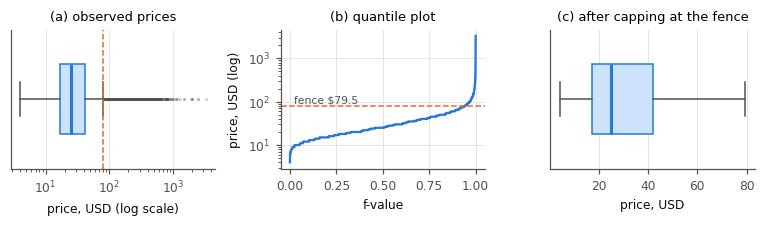

Takeaway: Prices are right-skewed: 6,867 bottles (6.2%) sit above the $79.5 fence and run to $3,300; capping keeps the rows but removes the tail.


In [19]:
fig, ax = plt.subplots(1, 3, figsize=(7.0, 2.1))
box_style = dict(vert=False, widths=0.5, patch_artist=True, boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE),
                 medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=INK2),
                 capprops=dict(color=INK2), flierprops=dict(marker='o', markersize=2, alpha=0.25,
                                                            markerfacecolor=INK2, markeredgecolor='none'))
ax[0].boxplot(observed, **box_style)
ax[0].set_xscale('log')
ax[0].axvline(fence, color=ORANGE, linestyle='--', linewidth=1)
ax[0].set(title='(a) observed prices', xlabel='price, USD (log scale)', yticks=[])

f_val = (np.arange(1, len(observed) + 1) - 0.5) / len(observed)
ax[1].plot(f_val, np.sort(observed.values), color=BLUE, linewidth=1.5)
ax[1].axhline(fence, color=ORANGE, linestyle='--', linewidth=1)
ax[1].set_yscale('log')
ax[1].set(title='(b) quantile plot', xlabel='f-value', ylabel='price, USD (log)')
ax[1].text(0.02, fence * 1.15, f'fence ${fence:g}', color=INK2, fontsize=7)

ax[2].boxplot(observed.clip(upper=fence), **box_style)
ax[2].set(title='(c) after capping at the fence', xlabel='price, USD', yticks=[])
fig.tight_layout()
save_fig(fig, 'fig_price_outliers')
takeaway('capPrice', f'Prices are right-skewed: {n_above:,} bottles ({100 * n_above / len(observed):.1f}%) sit above '
         f'the ${fence:g} fence and run to ${observed.max():,.0f}; capping keeps the rows but removes the tail.')

**What:** cap `price` at the fence in the encoded table, and keep the uncapped observed price as `price_raw`
for picking price bands in the tests. **Why not delete:** they are real luxury bottles (the most expensive ones
listed above), not entry errors, and deleting them would remove the top of the market. Capping stops a $3,300 bottle
from dominating a mean. `log(price)` was the other candidate (see the skewness check below). We cap because
the encoded `price` stays in dollars. Then we **re-check**: recompute the fence on the capped prices and confirm
that no value is above it.

In [20]:
df['price_raw'] = df.price.where(~df.price_imputed)    # observed dollars; NaN where the price was imputed
price_before = observed.copy()
df['price'] = df.price.clip(upper=fence)

capped = df.loc[~df.price_imputed, 'price']
cq1, cq3 = capped.quantile([0.25, 0.75])
fence_again = cq3 + 1.5 * (cq3 - cq1)
assert (capped > fence_again).sum() == 0
print(f're-check: fence on capped prices = {fence_again}, values above it = {(capped > fence_again).sum()}')

shape = pd.DataFrame({
    'price (raw)': [pearson_skew(price_before), stats.kurtosis(price_before)],
    'price (capped)': [pearson_skew(capped), stats.kurtosis(capped)],
    'log(price)': [pearson_skew(np.log(price_before)), stats.kurtosis(np.log(price_before))],
    'points': [pearson_skew(df.points), stats.kurtosis(df.points)],
}, index=['Pearson skewness 3(mean-median)/SD', 'excess kurtosis']).round(2)
print(shape)
keep('skewPriceRaw', shape.loc[shape.index[0], 'price (raw)'], lambda v: num(v, 2))
keep('skewPriceCap', shape.loc[shape.index[0], 'price (capped)'], lambda v: num(v, 2))
keep('kurtPriceRaw', shape.loc[shape.index[1], 'price (raw)'], lambda v: num(v, 1))
keep('kurtPriceCap', shape.loc[shape.index[1], 'price (capped)'], lambda v: num(v, 1))
log_step(df, '10 cap price at the IQR fence', '+price_raw')

re-check: fence on capped prices = 79.5, values above it = 0
                                    price (raw)  price (capped)  log(price)  points
Pearson skewness 3(mean-median)/SD         0.76            1.09        0.45    0.43
excess kurtosis                          808.94            0.11        0.74   -0.34
10 cap price at the IQR fence           119,895 rows x 12 cols   +price_raw


Capping removes the extreme tail (excess kurtosis collapses), but Pearson's coefficient *rises*. The SD shrinks far more
than the mean−median gap, because the bulk of prices is still right-skewed. So the plots use a log scale, and the
tests compare prices through **bands** rather than through a mean of price.

### 2.11 Description length
`desc_words` is the number of words in the tasting note. It is the explanatory variable in T2.

In [21]:
df['desc_words'] = df.description.str.split().str.len()
print(df.desc_words.describe().round(1).to_string())
log_step(df, '11 add desc_words', '+desc_words')

count    119895.0
mean         40.4
std          11.2
min           3.0
25%          33.0
50%          40.0
75%          47.0
max         135.0
11 add desc_words                       119,895 rows x 13 cols   +desc_words


### 2.12 Encoding and the 3M size check
Encoded table (Plan A): 5 numeric columns (`points`, `price` capped, `price_imputed` 0/1, `vintage`, `desc_words`),
plus `country` one-hot over the top 9 + Other (10 columns), plus `variety` one-hot over the top 10 + Other
(11 columns), for **26** columns. `points` is ordinal, so it stays an integer. Nominal attributes are one-hot,
because integer codes would invent an order. Rare levels merge into `Other` because a level with a few dozen wines
gives an unstable estimate. `winery` and `designation` are never one-hot encoded: thousands of near-empty columns
would be padding, not information.

In [22]:
def top_k(s, k):
    keep_levels = s.value_counts().index[:k]
    return s.where(s.isin(keep_levels), 'Other')


NUMERIC = ['points', 'price', 'price_imputed', 'vintage', 'desc_words']
country_k, variety_k = top_k(df.country, 9), top_k(df.variety, 10)
X = pd.concat([df[NUMERIC].astype(float),
               pd.get_dummies(country_k, prefix='country', dtype=int),
               pd.get_dummies(variety_k, prefix='variety', dtype=int)], axis=1)
assert X.shape[1] == 26

n, m = X.shape
print(f'Size check: {n:,} rows x {m} attributes = {n * m:,} >= 3,000,000 -> {n * m >= 3_000_000}')
assert n * m >= 3_000_000
rows_needed = -(-3_000_000 // m)
cells_if_deleted = (n - df.price_imputed.sum()) * m
print(f'rows needed: {rows_needed:,}; if missing-price rows were deleted: '
      f'{n - df.price_imputed.sum():,} x {m} = {cells_if_deleted:,} < 3M')
print(f'country Other: {(country_k == "Other").mean():.1%} of rows; variety Other: {(variety_k == "Other").mean():.1%}')
print('columns:', list(X.columns))

keep('rowsClean', n)
keep('colsEnc', m)
keep('cellsEnc', n * m)
keep('rowsNeeded', rows_needed)
keep('rowsIfDeleted', n - df.price_imputed.sum())
keep('cellsIfDeleted', cells_if_deleted)
keep('pctCountryOther', 100 * (country_k == 'Other').mean(), '{:.1f}')
keep('pctVarietyOther', 100 * (variety_k == 'Other').mean(), '{:.1f}')
keep('topCountries', ', '.join(country_k.value_counts().index.drop('Other')), '{}')
keep('topVarieties', ', '.join(variety_k.value_counts().index.drop('Other')), '{}')

Size check: 119,895 rows x 26 attributes = 3,117,270 >= 3,000,000 -> True
rows needed: 115,385; if missing-price rows were deleted: 111,511 x 26 = 2,899,286 < 3M
country Other: 5.7% of rows; variety Other: 44.3%
columns: ['points', 'price', 'price_imputed', 'vintage', 'desc_words', 'country_Argentina', 'country_Australia', 'country_Austria', 'country_Chile', 'country_France', 'country_Italy', 'country_Other', 'country_Portugal', 'country_Spain', 'country_US', 'variety_Bordeaux-style Red Blend', 'variety_Cabernet Sauvignon', 'variety_Chardonnay', 'variety_Merlot', 'variety_Other', 'variety_Pinot Noir', 'variety_Red Blend', 'variety_Riesling', 'variety_Rosé', 'variety_Sauvignon Blanc', 'variety_Syrah']


**Saved tables.** Both prepared tables are written to `data/` so they can be checked without re-running the
notebook: `winemag_clean.csv` is the readable cleaned table that Sections 4–6 start from, and `winemag_encoded.csv` is
the 26-column encoded table behind the size check. `raw_row` is the row id in the Kaggle file.

In [23]:
CLEAN, ENC = ROOT / 'data' / 'winemag_clean.csv', ROOT / 'data' / 'winemag_encoded.csv'
df.to_csv(CLEAN, index_label='raw_row')
X.to_csv(ENC, index_label='raw_row')
assert pd.read_csv(ENC, index_col=0).shape == X.shape
for f in (CLEAN, ENC):
    print(f'saved {f.relative_to(ROOT).as_posix()} ({f.stat().st_size / 1e6:.1f} MB)')

saved data/winemag_clean.csv (46.8 MB)
saved data/winemag_encoded.csv (9.0 MB)


In [24]:
prep = pd.DataFrame([
    ('Exact duplicate rows', f'{n_dup:,} dropped', 'one review scraped twice; keeping it inflates n and shrinks SEs'),
    ('Same note on two wines', f'{n_near} rows dropped (first kept)', 'titles differ, so the text was pasted twice; it would count twice in T2'),
    ('Missing country or variety', f'{n_cv} rows dropped', 'too few to matter; guessing a country would invent data'),
    ('Missing price (systematic by country)', f'{df.price_imputed.sum():,} filled with the country median and flagged',
     'deleting would drop the table below 3M cells; flagged rows are left out of every test'),
    ('Missing taster_name (systematic by country)', f'{NUM["nTasterMiss"]} filled with "Unknown"',
     f'the score exists; dropping would remove {rate_t.iloc[0]:.0%} of {rate_t.index[0]} reviews'),
    ('region_2, twitter handle, winery, designation', 'columns dropped', f'{NUM["pctRegionTwoMiss"]}% missing / repeats taster / ID-like ({NUM["wineryLevels"]} wineries)'),
    ('Double spaces, \\xa0 in names', 'collapsed and replaced', 'exact-match filters would silently miss rows'),
    ('Vintage buried in title', f'regex; {NUM["nVintageNaN"]} set to NaN', 'no year, NV or two years: a guessed vintage would be false data'),
    ('Synonym varieties', f'{n_syn:,} rows renamed', 'same grape under two names would split one level'),
    ('Prices above the IQR fence', f'{n_above:,} capped at ${fence:g}', 'real luxury bottles: keep the rows, stop them dominating means'),
    ('Nominal country, variety', 'one-hot, top 9 / top 10 + Other', 'integer codes would invent an order; rare levels are unstable'),
], columns=['Issue found', 'What we did', 'Why, and not the alternative'])
save_table(prep, 'prep')
save_table(pd.DataFrame(log), 'step_log')
pd.DataFrame(log)

,step,rows,cols,note
0,0 raw file,129971,13,
1,1 drop exact duplicates,119988,13,"-9,983"
2,2 drop shared descriptions,119955,13,-33
3,3 drop missing country/variety,119895,13,-60
4,4 impute price (country median),119895,14,+price_imputed flag
5,"5 taster_name -> ""Unknown""",119895,14,
6,6 drop 4 columns,119895,10,"region_2, taster_twitter_handle, winery, designation"
7,7 clean strings,119895,10,
8,8 extract vintage,119895,11,+vintage
9,9 merge synonym varieties,119895,11,


## 3. Before and after
"Before" is the raw file; "after" is the cleaned table (and, for attributes, the encoded one).

In [25]:
raw_obs = raw.price.dropna()
raw_q1, raw_q3 = raw_obs.quantile([0.25, 0.75])
raw_fence = raw_q3 + 1.5 * (raw_q3 - raw_q1)
ba = pd.DataFrame([
    ('Rows', f'{len(raw):,}', f'{len(df):,}'),
    ('Attributes', f'{raw.shape[1]}', f'{m} after encoding'),
    ('Exact duplicate rows', f'{raw.duplicated().sum():,}', '0'),
    ('Notes shared by two wines', f'{n_pairs} pairs', '0'),
    ('Missing price', f'{raw.price.isna().sum():,} ({raw.price.isna().mean():.1%})',
     f'0: {df.price_imputed.sum():,} imputed and flagged'),
    ('Missing taster_name', f'{raw.taster_name.isna().sum():,} ({raw.taster_name.isna().mean():.1%})', '0: "Unknown"'),
    ('Variety levels', f'{raw.variety.nunique()}', f'{df.variety.nunique()}'),
    (f'Prices above the ${raw_fence:g} fence', f'{(raw_obs > raw_fence).sum():,}', '0 (capped)'),
    ('Price skewness (Pearson)', f'{pearson_skew(raw_obs):.2f}', f'{pearson_skew(capped):.2f}'),
    ('Price excess kurtosis', f'{stats.kurtosis(raw_obs):.1f}', f'{stats.kurtosis(capped):.1f}'),
    ('Vintage', 'inside title text', f'numeric for {df.vintage.notna().sum():,} rows'),
], columns=['Measure', 'Before', 'After'])
save_table(ba, 'before_after')
keep('rowsLost', len(raw) - len(df))
ba

,Measure,Before,After
0,Rows,"129,971","119,895"
1,Attributes,13,26 after encoding
2,Exact duplicate rows,"9,983",0
3,Notes shared by two wines,33 pairs,0
4,Missing price,"8,996 (6.9%)","0: 8,384 imputed and flagged"
5,Missing taster_name,"26,244 (20.2%)","0: ""Unknown"""
6,Variety levels,707,698
7,Prices above the $79.5 fence,"7,241",0 (capped)
8,Price skewness (Pearson),0.76,1.09
9,Price excess kurtosis,829.5,0.1


## 4. EDA, basic questions and problem statements
EDA uses the rows with an **observed** price (`T`, the same rows the tests use); imputed prices are left out.

In [26]:
T = df[~df.price_imputed].copy()
assert T.price_raw.notna().all() and not T.price_imputed.any()
T['is90'] = T.points >= 90
keep('rowsTested', len(T))
print(f'{len(T):,} rows with an observed price')

111,511 rows with an observed price


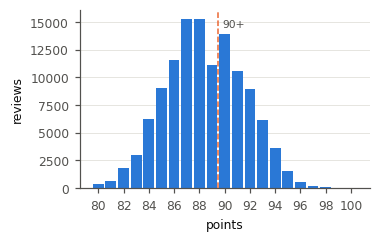

Takeaway: Scores are a narrow bell from 80 to 100 (mean 88.4, SD 3.1) with nothing below 80 because lower scores are not published; 38% reach 90+.


In [27]:
fig, ax = plt.subplots(figsize=(3.4, 2.1))
counts = df.points.value_counts().sort_index()
ax.bar(counts.index, counts.values, width=0.85, color=BLUE)
ax.axvline(89.5, color=ORANGE, linestyle='--', linewidth=1)
ax.text(89.8, counts.max() * 0.95, '90+', color=INK2, fontsize=7)
ax.set(xlabel='points', ylabel='reviews', xticks=range(80, 101, 2))
ax.grid(axis='x', visible=False)
save_fig(fig, 'fig_points')
share90 = (df.points >= 90).mean()
keep('pointsMean', df.points.mean(), '{:.2f}')
keep('pointsMedian', df.points.median(), '{:g}')
keep('pointsSD', df.points.std(), '{:.2f}')
keep('pointsSkew', pearson_skew(df.points), lambda v: num(v, 2))
keep('pctNinety', 100 * share90, '{:.1f}')
takeaway('capPoints', f'Scores are a narrow bell from 80 to 100 (mean {df.points.mean():.1f}, SD {df.points.std():.1f}) '
         f'with nothing below 80 because lower scores are not published; {share90:.0%} reach 90+.')

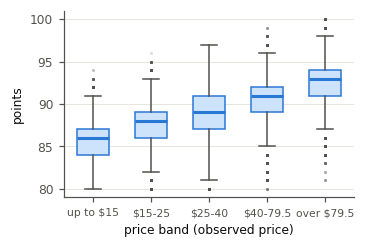

Takeaway: Median score climbs from 86 (up to $15) to 93 (over $79.5); r(log price, points) = 0.62, so any fair comparison must hold price fixed.


In [28]:
BAND_EDGES = [0, 15, 25, 40, fence, np.inf]
BAND_LABELS = ['up to $15', '$15-25', '$25-40', f'$40-{fence:g}', f'over ${fence:g}']
T['price_band'] = pd.cut(T.price_raw, BAND_EDGES, labels=BAND_LABELS)

fig, ax = plt.subplots(figsize=(3.4, 2.2))
groups = [T.points[T.price_band == b] for b in BAND_LABELS]
ax.boxplot(groups, widths=0.55, patch_artist=True, boxprops=dict(facecolor='#cde2fb', edgecolor=BLUE),
           medianprops=dict(color=BLUE, linewidth=2), whiskerprops=dict(color=INK2), capprops=dict(color=INK2),
           flierprops=dict(marker='o', markersize=2, alpha=0.2, markerfacecolor=INK2, markeredgecolor='none'))
ax.set_xticks(range(1, 6), [b.replace('$', r'\$') for b in BAND_LABELS], fontsize=7)
ax.set(ylabel='points', xlabel='price band (observed price)')
ax.grid(axis='x', visible=False)
save_fig(fig, 'fig_price_points')
band_median = T.groupby('price_band', observed=True).points.median()
r_logprice = np.corrcoef(np.log(T.price_raw), T.points)[0, 1]
keep('rLogPrice', r_logprice, '{:.2f}')
takeaway('capPricePoints', f'Median score climbs from {band_median.iloc[0]:g} (up to $15) to {band_median.iloc[-1]:g} '
         f'(over ${fence:g}); r(log price, points) = {r_logprice:.2f}, so any fair comparison must hold price fixed.')

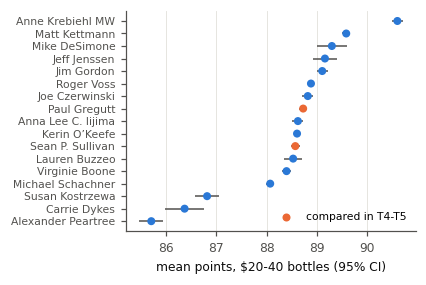

Takeaway: At the same $20-40 price, critic means span 4.9 points, from Alexander Peartree (85.7) to Anne Krebiehl MW (90.6): who tastes may matter as much as what is tasted.


In [29]:
mid = T[T.price_raw.between(20, 40)]
by_taster = (mid[mid.taster_name != 'Unknown'].groupby('taster_name').points
             .agg(mean='mean', sd='std', n='size').query('n >= 100').sort_values('mean'))
by_taster['half'] = stats.t.ppf(0.975, by_taster.n - 1) * by_taster.sd / np.sqrt(by_taster.n)

fig, ax = plt.subplots(figsize=(3.4, 2.6))
pair = ['Paul Gregutt', 'Sean P. Sullivan']
colors = [ORANGE if t in pair else BLUE for t in by_taster.index]
ax.errorbar(by_taster['mean'], range(len(by_taster)), xerr=by_taster.half, fmt='none', ecolor=INK2, elinewidth=1)
ax.scatter(by_taster['mean'], range(len(by_taster)), c=colors, s=18, zorder=3)
ax.set_yticks(range(len(by_taster)), by_taster.index, fontsize=7)
lo_tick, hi_tick = np.floor((by_taster['mean'] - by_taster.half).min()), np.ceil((by_taster['mean'] + by_taster.half).max())
ax.set_xticks(np.arange(lo_tick, hi_tick + 1), [f'{v:.0f}' for v in np.arange(lo_tick, hi_tick + 1)])
ax.set(xlabel='mean points, $20-40 bottles (95% CI)')
ax.grid(axis='y', visible=False)
ax.scatter([], [], c=ORANGE, s=18, label='compared in T4-T5')
ax.legend(loc='lower right', fontsize=7)
save_fig(fig, 'fig_tasters')
gap = by_taster['mean'].max() - by_taster['mean'].min()
keep('tasterGap', gap, '{:.1f}')
keep('nTastersShown', len(by_taster))
takeaway('capTasters', f'At the same $20-40 price, critic means span {gap:.1f} points, from '
         f'{by_taster.index[0]} ({by_taster["mean"].iloc[0]:.1f}) to {by_taster.index[-1]} '
         f'({by_taster["mean"].iloc[-1]:.1f}): who tastes may matter as much as what is tasted.')

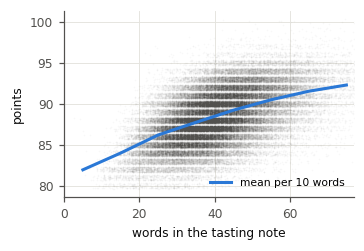

Takeaway: Longer notes come with higher scores along a near-straight line (r = 0.54), from about 82 points for the shortest notes to 92 for the longest.


In [30]:
fig, ax = plt.subplots(figsize=(3.4, 2.2))
jitter_x, jitter_y = rng.uniform(-0.45, 0.45, len(T)), rng.uniform(-0.35, 0.35, len(T))   # both are whole numbers
ax.scatter(T.desc_words + jitter_x, T.points + jitter_y, s=1, alpha=0.04, color=INK2, rasterized=True, linewidths=0)
word_bins = pd.cut(T.desc_words, np.arange(0, T.desc_words.quantile(0.995) + 10, 10))
binned = T.groupby(word_bins, observed=True).points.mean()
ax.plot([b.mid for b in binned.index], binned.values, color=BLUE, linewidth=2, label='mean per 10 words')
ax.set(xlabel='words in the tasting note', ylabel='points', xlim=(0, T.desc_words.quantile(0.995)))
ax.legend(loc='lower right', fontsize=7)
save_fig(fig, 'fig_words')
r_words = np.corrcoef(T.desc_words, T.points)[0, 1]
takeaway('capWords', f'Longer notes come with higher scores along a near-straight line (r = {r_words:.2f}), '
         f'from about {binned.iloc[0]:.0f} points for the shortest notes to {binned.iloc[-1]:.0f} for the longest.')

### Basic questions

In [31]:
best = (T.groupby('country').points.agg(mean='mean', n='size').query('n >= 500')
        .sort_values('mean', ascending=False))
top_varieties = df.variety.value_counts()
print(f'Q1 Do pricier wines score higher?  r(log price, points) = {r_logprice:.2f}')
print('Q2 Which country scores best (countries with at least 500 rated, priced wines)?')
print(best.head(5).round(2).to_string())
print('Q3 Which varieties are reviewed most?')
print(top_varieties.head(5).to_string())
keep('bestCountry', best.index[0], '{}')
keep('bestCountryMean', best['mean'].iloc[0], '{:.2f}')
keep('topVariety', top_varieties.index[0], '{}')
keep('topVarietyN', top_varieties.iloc[0])

Q1 Do pricier wines score higher?  r(log price, points) = 0.62
Q2 Which country scores best (countries with at least 500 rated, priced wines)?
            mean      n
country                
Austria    90.22   2535
Germany    89.88   1951
France     88.75  16286
Italy      88.63  15492
Australia  88.57   2169
Q3 Which varieties are reviewed most?
variety
Pinot Noir                  12274
Chardonnay                  10864
Cabernet Sauvignon           8835
Red Blend                    8229
Bordeaux-style Red Blend     6469


### Problem statements
The basic questions look at one column at a time, and price drives the score (figure above). Ours compare
**like with like** at a fixed price and ask whether things that should *not* move a score do move it:

* **P1 (primary).** Wines of the same state, price and vintage go to different critics. Does the critic change
  the score? We look at both its level (share of 90+) and its spread.
* **P2.** At the same price, do Old-World wines score differently from New-World wines, and does that survive
  holding the critic fixed?
* **P3.** Is the length of the tasting note a signal of the score?
* **P4.** At what price does a 90+ score become likely?

**Why they are novel:** each needs a like-for-like comparison or a derived feature (price band, Old/New World,
vintage overlap, word count) that no single column records.

## 5. Hypothesis tests

All tests use `T`, the rows with an observed price. Imputed prices are left out (asserted above). α = 0.05 throughout.
Every confidence interval is a two-sided 95% interval. With samples this large almost everything is significant,
so each test also fixes, **before running**, the smallest difference that would matter. The verdict reads the
CI against that threshold: **matters** (CI entirely beyond it), **does not matter** (CI entirely inside it) or
**unclear** (CI straddles it).

### T1 (P2): Old World vs New World at the same price

**a) Written before running the test**

| | |
|---|---|
| Groups | Old World = Europe and the eastern Mediterranean/Caucasus; New World = the Americas, Australia, NZ, South Africa (China, India, Egypt, Morocco left out) |
| Rows | observed price $20–40 (around the median, where both groups are large) |
| H₀ | μ_Old − μ_New = 0 |
| H₁ | μ_Old − μ_New ≠ 0 |
| α, side | 0.05, two-sided (P2 asks *whether* origin matters, not which way) |
| Test | two-sample t; an F-test for equal variances runs first and decides pooled vs Welch (Welch if F rejects) |
| Smallest difference that matters | **1 point**: scores are published as whole points, so a smaller gap does not change the printed score of a typical bottle |

In [32]:
OLD_WORLD = ['Armenia', 'Austria', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czech Republic',
             'England', 'France', 'Georgia', 'Germany', 'Greece', 'Hungary', 'Israel', 'Italy', 'Lebanon',
             'Luxembourg', 'Macedonia', 'Moldova', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia',
             'Spain', 'Switzerland', 'Turkey', 'Ukraine']
NEW_WORLD = ['Argentina', 'Australia', 'Brazil', 'Canada', 'Chile', 'Mexico', 'New Zealand', 'Peru',
             'South Africa', 'US', 'Uruguay']
print('not classified:', sorted(set(df.country) - set(OLD_WORLD) - set(NEW_WORLD)))
LO, HI = 20, 40
DELTA1 = 1.0

mid = T[T.price_raw.between(LO, HI)].copy()
mid['world'] = np.select([mid.country.isin(OLD_WORLD), mid.country.isin(NEW_WORLD)], ['Old', 'New'], 'neither')
old, new = mid.points[mid.world == 'Old'], mid.points[mid.world == 'New']
desc1 = pd.DataFrame({'Old': old.describe(), 'New': new.describe()}).T[['count', 'mean', '50%', 'std']]
print(desc1.round(3))
keep('oldN', len(old))
keep('newN', len(new))
keep('oldMean', old.mean(), '{:.2f}')
keep('newMean', new.mean(), '{:.2f}')
keep('oldSD', old.std(), '{:.2f}')
keep('newSD', new.std(), '{:.2f}')

not classified: ['China', 'Egypt', 'India', 'Morocco']
       count    mean   50%    std
Old  18047.0  88.828  89.0  2.390
New  27929.0  88.232  88.0  2.733


In [33]:
f1 = f_test(old, new)
print('Step 1, equal variances?')
show(f1)
t1 = welch_t(old, new) if f1['p'] < ALPHA else pooled_t(old, new)
print('\nStep 2, main test (chosen by the F-test):')
show(t1)
assert np.isclose(t1['stat'], stats.ttest_ind(old, new, equal_var=t1['test'] == 'pooled t').statistic)
v1 = matters(t1['lo'], t1['hi'], DELTA1)
print(f'Practical verdict vs {DELTA1} point: {v1}')
keep_test('oneF', f1, d=3)
keep_test('one', t1)
keep('oneTest', t1['test'], '{}')
keep('oneVerdict', v1, '{}')

Step 1, equal variances?
F: statistic = 0.765, df = 18,046, 27,928, p = 7.94e-86 -> reject H0; estimate = 0.7648, 95% CI [0.7449, 0.7854]

Step 2, main test (chosen by the F-test):
Welch t: statistic = 24.643, df = 42,033, p = 3.84e-133 -> reject H0; estimate = 0.5955, 95% CI [0.5481, 0.6428]
Practical verdict vs 1.0 point: does not matter


**b) Other tests considered.** Two independent groups with a numeric response and unknown σ call for a two-sample t-test.
* *Pooled t-test* assumes equal variances, which the F-test above rejects. We run it anyway (below).
* *Two-sample z-test* needs the population σ. With n in the tens of thousands, the CLT makes it almost identical to t, so we run it too.
* *Paired t-test* does not apply: no wine is in both groups.
* *χ² test for independence* on Old/New × 90+ would throw away the score's detail.

In [34]:
alt1 = [pooled_t(old, new), z_two_means(old, new)]
for r in alt1:
    show(r)
keep_test('onePooled', alt1[0])
keep_test('oneZ', alt1[1])

pooled t: statistic = 23.947, df = 45,974, p = 5.86e-126 -> reject H0; estimate = 0.5955, 95% CI [0.5467, 0.6442]
two-sample z: statistic = 24.643, df = -, p = 4.35e-134 -> reject H0; estimate = 0.5955, 95% CI [0.5481, 0.6428]


**Digging deeper: is "origin" really the critic?** Old-World and New-World wines are tasted by different critics, so
the Old−New gap mixes origin with critic. Michael Schachner tastes both Spain (Old) and Chile/Argentina (New),
so within his reviews the critic is held fixed. The same Welch test is run on his $20–40 wines.

In [35]:
mix = pd.crosstab(mid.taster_name, mid.world, normalize='columns')[['Old', 'New']]
print('Share of each group reviewed by each critic (top 6 per group):')
print(mix.sort_values('Old', ascending=False).head(6).round(3).to_string())

sch = mid[mid.taster_name == 'Michael Schachner']
s_old, s_new = sch.points[sch.country == 'Spain'], sch.points[sch.country.isin(['Chile', 'Argentina'])]
print(f'\nSchachner: Spain n = {len(s_old):,} (mean {s_old.mean():.2f}), '
      f'Chile+Argentina n = {len(s_new):,} (mean {s_new.mean():.2f})')
t1s = welch_t(s_old, s_new)
show(t1s)
v1s = matters(t1s['lo'], t1s['hi'], DELTA1)
print('Practical verdict:', v1s)
keep_test('oneSch', t1s)
keep('oneSchVerdict', v1s, '{}')
keep('oneSchOldN', len(s_old))
keep('oneSchNewN', len(s_new))
keep('oneTopOldTaster', mix.Old.idxmax(), '{}')
keep('oneTopOldShare', 100 * mix.Old.max(), '{:.0f}')
keep('oneTopNewTaster', mix.New.idxmax(), '{}')
keep('oneTopNewShare', 100 * mix.New.max(), '{:.0f}')
SUMMARY.append(dict(test='T1', question='Old vs New World, $20-40', method=t1['test'], res=t1, delta='1 point', verdict=v1))

Share of each group reviewed by each critic (top 6 per group):
world                 Old    New
taster_name                     
Roger Voss          0.373  0.000
Kerin O’Keefe       0.202  0.000
Unknown             0.126  0.271
Michael Schachner   0.103  0.074
Anne Krebiehl MW    0.088  0.000
Anna Lee C. Iijima  0.040  0.038

Schachner: Spain n = 1,831 (mean 88.21), Chile+Argentina n = 1,927 (mean 88.07)
Welch t: statistic = 1.639, df = 3,730, p = 0.101 -> fail to reject H0; estimate = 0.1422, 95% CI [-0.0279, 0.3122]
Practical verdict: does not matter


**c) Result and reading.** Old-World wines at $20–40 score higher than New-World ones, and the gap is highly
significant. But the whole 95% CI lies below 1 point, so by our standard **the difference does not matter**: pooled t
and z agree. Holding the critic fixed (Schachner), the gap shrinks further and is no longer significant. Most of the
raw Old−New gap reflects *who* tastes the wines rather than *where* they come from, which motivates P1.

### T2 (P3): Is the length of the tasting note a signal of the score?

**a) Written before running the test**

| | |
|---|---|
| ρ | Pearson correlation between `desc_words` and `points`, all rows with an observed price |
| H₀ | ρ ≤ 0 (the equality ρ = 0 is the boundary tested) |
| H₁ | ρ > 0 |
| α, side | 0.05, one-sided (right): P3 claims longer notes go with *higher* scores |
| Test | t-test on the correlation coefficient, t = r√(n−2)/√(1−r²), df = n − 2 |
| Smallest effect that matters | **ρ = 0.3**: below that, length explains under 9% of the score variance and is useless for guessing a score |

In [36]:
DELTA2 = 0.3
t2 = r_test(T.desc_words, T.points, side='greater')
show(t2)
check = stats.pearsonr(T.desc_words, T.points, alternative='greater')
assert np.isclose(t2['est'], check.statistic)
slope = t2['est'] * T.points.std() / T.desc_words.std()
v2 = 'matters' if t2['lo'] >= DELTA2 else ('does not matter' if t2['hi'] < DELTA2 else 'unclear')
print(f'slope: {10 * slope:.2f} points per 10 extra words; verdict vs rho = {DELTA2}: {v2}')
keep_test('two', t2, d=3)
keep('twoSlope', 10 * slope, '{:.2f}')
keep('twoRsq', 100 * t2['est'] ** 2, '{:.0f}')
keep('twoVerdict', v2, '{}')
keep('wordsMedian', T.desc_words.median(), '{:g}')

t on Pearson r: statistic = 213.066, df = 111,509, p = 0 -> reject H0; estimate = 0.5379, 95% CI [0.5337, 0.5420]
slope: 1.49 points per 10 extra words; verdict vs rho = 0.3: matters


**b) Other tests considered.** Both variables are numeric and measured on the same wine, so the question is one of
association, which calls for the t-test on Pearson r (df = n − 2). r has no units, so one threshold works for any
scale, and Fisher z gives its CI.
* *Welch t on long vs short notes* (split at the median word count) answers a cruder question, but its result is in points, so we run it.
* *Two-sample z* gives the same result at this n.
* *χ² test for independence* on length bands × 90+ would need arbitrary bins.
* *Paired t* has nothing to pair.

In [37]:
med_words = T.desc_words.median()
long_, short = T.points[T.desc_words > med_words], T.points[T.desc_words <= med_words]
alt2 = welch_t(long_, short, side='greater')
show(alt2)
keep_test('twoWelch', alt2)

Welch t: statistic = 160.406, df = 108,743, p = 0 -> reject H0; estimate = 2.6940, 95% CI [2.6611, 2.7269]


**Digging deeper: is the correlation produced by critic style or price?** Some critics write long notes *and*
score high, and expensive wines may get both longer notes and higher scores. So we recompute r within each
critic (critic fixed) and within the $20–40 band (price fixed).

In [38]:
rows = []
for name, g in T[T.taster_name != 'Unknown'].groupby('taster_name'):
    if len(g) >= 1000:
        r = r_test(g.desc_words, g.points, side='greater')
        rows.append((name, len(g), r['est'], r['lo'], r['hi']))
within = pd.DataFrame(rows, columns=['taster', 'n', 'r', 'lo', 'hi']).sort_values('r', ascending=False)
band_r = r_test(mid.desc_words, mid.points, side='greater')
print(within.round(3).to_string(index=False))
print('\nwithin the $20-40 band:', end=' ')
show(band_r)
keep('twoTasterMin', within.r.min(), '{:.2f}')
keep('twoTasterMax', within.r.max(), '{:.2f}')
keep('twoTasterMinName', within.taster.iloc[-1], '{}')
keep('twoTasterCount', len(within))
keep('twoTastersAbove', (within.lo >= DELTA2).sum())
keep('twoBandR', band_r['est'], '{:.2f}')
save_table(within.assign(n=within.n.map('{:,}'.format), r=within.r.map(lambda v: num(v, 2)),
                         CI=[Tex(f'{a:.2f} to {b:.2f}') for a, b in zip(within.lo, within.hi)])
           [['taster', 'n', 'r', 'CI']], 't2_tasters')
SUMMARY.append(dict(test='T2', question='note length vs points', method='t on Pearson r', res=t2, delta='rho = 0.3', verdict=v2))

            taster     n     r    lo    hi
     Lauren Buzzeo  1581 0.749 0.726 0.770
  Anne Krebiehl MW  3027 0.715 0.697 0.732
        Jim Gordon  3761 0.637 0.618 0.656
        Roger Voss 18543 0.563 0.553 0.573
    Virginie Boone  8681 0.562 0.547 0.576
     Kerin O’Keefe  8872 0.555 0.540 0.569
 Michael Schachner 13863 0.551 0.540 0.563
  Sean P. Sullivan  4422 0.503 0.480 0.524
     Matt Kettmann  5642 0.502 0.482 0.521
    Joe Czerwinski  4642 0.478 0.455 0.499
      Paul Gregutt  8836 0.452 0.435 0.468
Anna Lee C. Iijima  3974 0.387 0.360 0.413
   Susan Kostrzewa  1005 0.203 0.143 0.262

within the $20-40 band: t on Pearson r: statistic = 118.455, df = 45,979, p = 0 -> reject H0; estimate = 0.4835, 95% CI [0.4765, 0.4905]


**c) Result and reading.** The correlation is strongly positive, and its whole CI lies above 0.3, so **it matters**:
note length tracks the score. The relationship holds within almost every critic and within one price band, so
critic style and price do not produce it. The direction of cause is unknown, and most likely critics write more about
wines they like.

### T3 (P4): Does the price band change the chance of a 90+ score?

**a) Written before running the test**

| | |
|---|---|
| Table | price band (5 bands of observed price: ≤ \$15, \$15–25, \$25–40, \$40–79.5, > \$79.5, the last cut being the IQR fence) × 90+ (yes/no) |
| H₀ | 90+ status is independent of price band (the same 90+ share in every band) |
| H₁ | the 90+ share differs between bands |
| α, side | 0.05; χ² uses the upper tail, since any departure from independence raises χ² |
| Test | χ² test for independence, expected count = row total × column total / grand total, df = (5−1)(2−1) = 4 |
| Smallest difference that matters | **5 percentage points** in 90+ share between adjacent bands (one more 90+ bottle in every twenty) |

In [39]:
DELTA3 = 0.05
obs3 = pd.crosstab(T.price_band, T.is90)
expected3 = np.outer(obs3.sum(axis=1), obs3.sum(axis=0)) / obs3.values.sum()
chi2_3 = ((obs3.values - expected3) ** 2 / expected3).sum()
dof3 = (obs3.shape[0] - 1) * (obs3.shape[1] - 1)
p3 = stats.chi2.sf(chi2_3, dof3)
assert np.isclose(chi2_3, stats.chi2_contingency(obs3, correction=False)[0])
assert expected3.min() >= 5
print(obs3)
print(f'smallest expected count = {expected3.min():,.0f}')
t3 = dict(test='chi-square independence', stat=chi2_3, df=dof3, p=p3, est=np.nan, lo=np.nan, hi=np.nan)
print(f'chi-square = {chi2_3:,.1f}, df = {dof3}, p = {p3:.3g} -> {decide(p3)}')
keep('threeStat', chi2_3, '{:,.0f}')
keep('threeDf', dof3)
keep('threeP', p3, tex_p)
keep('threeDecision', decide(p3), lambda s: s.replace('H0', r'\ensuremath{H_0}'))
keep('threeMinExp', expected3.min(), '{:,.0f}')

is90        False  True 
price_band              
up to $15   22066   1190
$15-25      25370   7759
$25-40      14120  11864
$40-79.5     6883  15392
over $79.5    974   5893
smallest expected count = 2,592
chi-square = 30,191.9, df = 4, p = 0 -> reject H0


price band      n 90+ share       95% CI step up from previous band verdict
 up to $15 23,256     5.1\%   4.8 to 5.4                          -       -
    $15-25 33,129    23.4\% 23.0 to 23.9    +18.3 pp (17.8 to 18.8) matters
    $25-40 25,984    45.7\% 45.1 to 46.3    +22.2 pp (21.5 to 23.0) matters
  $40-79.5 22,275    69.1\% 68.5 to 69.7    +23.4 pp (22.6 to 24.3) matters
over $79.5  6,867    85.8\% 85.0 to 86.6    +16.7 pp (15.7 to 17.7) matters


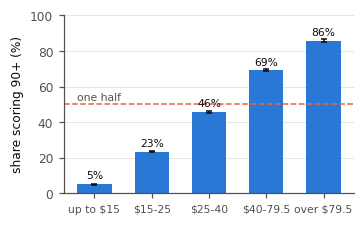

Takeaway: The chance of a 90+ score rises from 5% (up to $15) to 86% (over $79.5) and first passes one half in the $40-79.5 band.


In [40]:
k = obs3[True]
nb = obs3.sum(axis=1)
share = k / nb
half = Z975 * np.sqrt(share * (1 - share) / nb)
steps = [z_two_props(k.iloc[i + 1], nb.iloc[i + 1], k.iloc[i], nb.iloc[i]) for i in range(len(k) - 1)]
bands = pd.DataFrame({
    'price band': BAND_LABELS,
    'n': nb.map('{:,}'.format).values,
    '90+ share': [Tex(f'{100 * s:.1f}\\%') for s in share],
    '95% CI': [Tex(f'{100 * (s - h):.1f} to {100 * (s + h):.1f}') for s, h in zip(share, half)],
    'step up from previous band': ['-'] + [Tex(f'+{100 * r["est"]:.1f} pp ({100 * r["lo"]:.1f} to {100 * r["hi"]:.1f})')
                                         for r in steps],
    'verdict': ['-'] + [matters(r['lo'], r['hi'], DELTA3) for r in steps],
})
save_table(bands, 't3_bands')
print(bands.to_string(index=False))
first_likely = share[share > 0.5].index[0]
keep('threeFirstLikely', first_likely.replace('$', r'\$'), '{}')
keep('threeShareLow', 100 * share.iloc[0], '{:.1f}')
keep('threeShareHigh', 100 * share.iloc[-1], '{:.1f}')
keep('threeStepsMatter', sum(matters(r['lo'], r['hi'], DELTA3) == 'matters' for r in steps))
for i, r in enumerate(steps, start=1):
    keep(f'threeStep{i}', 100 * r['est'], '{:.1f}')

fig, ax = plt.subplots(figsize=(3.4, 2.1))
ax.bar(range(5), 100 * share.values, width=0.6, color=BLUE)
ax.errorbar(range(5), 100 * share.values, yerr=100 * half.values, fmt='none', ecolor=INK, elinewidth=1, capsize=2)
ax.axhline(50, color=ORANGE, linestyle='--', linewidth=1)
ax.text(-0.3, 52, 'one half', color=INK2, fontsize=7)
for i, s in enumerate(share.values):
    ax.text(i, 100 * s + 3, f'{100 * s:.0f}%', ha='center', fontsize=7, color=INK)
ax.set_xticks(range(5), [b.replace('$', r'\$') for b in BAND_LABELS], fontsize=7)
ax.set(ylabel='share scoring 90+ (%)', ylim=(0, 100))
ax.grid(axis='x', visible=False)
save_fig(fig, 'fig_band90')
takeaway('capBand', f'The chance of a 90+ score rises from {100 * share.iloc[0]:.0f}% (up to $15) to '
         f'{100 * share.iloc[-1]:.0f}% (over ${fence:g}) and first passes one half in the {first_likely} band.')

**b) Other tests considered.** Both variables are categorical and there are five bands, not two, which calls for the
χ² test for independence. Its large-sample approximation holds, since the smallest expected count printed above is far
above 5. A χ² statistic has no single estimate with a CI, so part c) reports each band's 90+ share and each step
between adjacent bands, with 95% CIs, and judges the steps against the 5-percentage-point threshold.
* *z-test for two proportions*, top band vs bottom band, uses only two of the five bands, but it gives an
  interval in percentage points, so we run it.
* *t-test on Pearson r* between log price and points treats price as continuous and the score as numeric,
  which answers a different question than "how likely is a 90+?". We run it as a cross-check.
* *χ² goodness of fit* needs a hypothesised distribution of 90+ across bands, and we have none.

In [41]:
alt3 = z_two_props(k.iloc[-1], nb.iloc[-1], k.iloc[0], nb.iloc[0])
z_sm, p_sm = proportions_ztest([k.iloc[-1], k.iloc[0]], [nb.iloc[-1], nb.iloc[0]])
assert np.isclose(alt3['stat'], z_sm)
show(alt3)
alt3b = r_test(np.log(T.price_raw), T.points, side='greater')
show(alt3b)
keep_test('threeZ', alt3, d=1, scale=100)
keep_test('threeR', alt3b, d=3)
SUMMARY.append(dict(test='T3', question='price band x 90+', method='chi-square independence', res=t3,
                    delta='5 pp between adjacent bands',
                    verdict=f'{NUM["threeStepsMatter"]} of 4 steps matter'))

two-proportion z: statistic = 138.554, df = -, p = 0 -> reject H0; estimate = 0.8070, 95% CI [0.7983, 0.8157]
t on Pearson r: statistic = 262.328, df = 111,509, p = 0 -> reject H0; estimate = 0.6178, 95% CI [0.6141, 0.6214]


**c) Result and reading.** 90+ status depends on price band. Every step up between adjacent bands is larger than 5
percentage points, with its whole CI beyond the threshold, so **every step matters**. A 90+ score first becomes more
likely than not in the $40–79.5 band, which answers P4.

### T4 (P1, primary): Same wines, different critic. Does the share of 90+ scores change?

Paul Gregutt and Sean P. Sullivan both review **Washington** wines. Before writing the hypotheses we check that
their wines are comparable. They are in the same state and the same $20–40 band, but the critics took turns
over time (figure below), so we also keep only **vintages that both reviewed at least 25 times**. Otherwise a
difference between critics would partly be a difference between vintages.

taster_name  Paul Gregutt  Sean P. Sullivan
vintage                                    
2003.0                  8                 0
2004.0                 39                 0
2005.0                187                 0
2006.0                200                 0
2007.0                223                 1
2008.0                316                 8
2009.0                366                27
2010.0                328               109
2011.0                235               180
2012.0                118               490
2013.0                 17               546
2014.0                  0               418
2015.0                  2               172
2016.0                  0                73
common vintages: [2009, 2010, 2011, 2012]


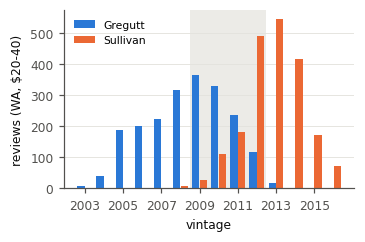

Takeaway: Gregutt and Sullivan reviewed Washington in turn; only the 2009-2012 vintages (shaded) have at least 25 wines from both, so T4 and T5 use only those.


In [42]:
PAIR = ['Paul Gregutt', 'Sean P. Sullivan']
wa = T[(T.province == 'Washington') & T.price_raw.between(LO, HI) & T.taster_name.isin(PAIR)]
vint = pd.crosstab(wa.vintage, wa.taster_name)[PAIR]
common = vint[(vint >= 25).all(axis=1)].index
print(vint.loc[2003:2016].astype(int).to_string())
print('common vintages:', [int(v) for v in common])

fig, ax = plt.subplots(figsize=(3.4, 2.1))
yrs = vint.loc[2003:2016].index.astype(int)
ax.axvspan(common.min() - 0.5, common.max() + 0.5, color=GRID, alpha=0.7, linewidth=0)
ax.bar(yrs - 0.2, vint.loc[2003:2016, PAIR[0]], width=0.38, color=BLUE, label='Gregutt')
ax.bar(yrs + 0.2, vint.loc[2003:2016, PAIR[1]], width=0.38, color=ORANGE, label='Sullivan')
ax.set(xlabel='vintage', ylabel='reviews (WA, $20-40)', xticks=yrs[::2])
ax.grid(axis='x', visible=False)
ax.legend(fontsize=7, loc='upper left')
save_fig(fig, 'fig_wa_vintages')
keep('fourVintFrom', int(common.min()), '{}')
keep('fourVintTo', int(common.max()), '{}')
takeaway('capVintages', f'Gregutt and Sullivan reviewed Washington in turn; only the {int(common.min())}-'
         f'{int(common.max())} vintages (shaded) have at least 25 wines from both, so T4 and T5 use only those.')

**a) Written before running the test**

| | |
|---|---|
| Rows | Washington, observed price $20–40, the shared vintages above |
| p_G, p_S | share of 90+ scores given by Gregutt and by Sullivan |
| H₀ | p_G − p_S = 0 |
| H₁ | p_G − p_S ≠ 0 |
| α, side | 0.05, two-sided (no prior reason to expect either critic to be the more generous) |
| Test | z-test for two proportions, pooled rate under H₀ (needs n·p̂ ≥ 10 in each group, checked below) |
| Smallest difference that matters | **5 percentage points**: one more 90+ label in every twenty bottles, enough to change what a shelf-talker shows |

In [43]:
DELTA4 = 0.05
like = wa[wa.vintage.isin(common)]
g, s = like.points[like.taster_name == PAIR[0]], like.points[like.taster_name == PAIR[1]]
k1, n1, k2, n2 = (g >= 90).sum(), len(g), (s >= 90).sum(), len(s)
assert min(k1, n1 - k1, k2, n2 - k2) >= 10
print(f'Gregutt: {k1}/{n1} = {k1 / n1:.3f}   Sullivan: {k2}/{n2} = {k2 / n2:.3f}')
both = set(like.title[like.taster_name == PAIR[0]]) & set(like.title[like.taster_name == PAIR[1]])
print(f'wines scored by both critics: {len(both)} of {like.title.nunique():,}')
t4 = z_two_props(k1, n1, k2, n2)
z_sm, p_sm = proportions_ztest([k1, k2], [n1, n2])
assert np.isclose(t4['stat'], z_sm) and np.isclose(t4['p'], p_sm)
show(t4)
v4 = matters(t4['lo'], t4['hi'], DELTA4)
print('Practical verdict vs 5 pp:', v4)
keep('fourGN', n1)
keep('fourSN', n2)
keep('fourGShare', 100 * k1 / n1, '{:.1f}')
keep('fourSShare', 100 * k2 / n2, '{:.1f}')
keep('fourBoth', len(both))
keep_test('four', t4, d=1, scale=100)
keep('fourVerdict', v4, '{}')

Gregutt: 516/1047 = 0.493   Sullivan: 305/806 = 0.378
wines scored by both critics: 1 of 1,851
two-proportion z: statistic = 4.916, df = -, p = 8.85e-07 -> reject H0; estimate = 0.1144, 95% CI [0.0693, 0.1596]
Practical verdict vs 5 pp: matters


**b) Other tests considered.** The two critics scored almost entirely different wines (the overlap is printed above),
so the groups are independent, and the outcome is yes/no. That calls for the z-test for two proportions: pooled rate
for the test, unpooled SE for the CI. Each group has far more than 10 scores on each side of 90, so the normal
approximation holds.
* *χ² test for independence* on the 2×2 table (critic × 90+) is the same test (z² = χ²) but gives no
  signed interval. We run it to confirm.
* *Welch t on mean points* compares the whole score, not the 90+ line. We run it with a 1-point threshold.
  Welch, not pooled, because T5 shows the variances differ.
* *Paired t* would need the same wines scored by both critics, and almost none are: far too few pairs to test.
* *One-proportion z* against a fixed rate would need a known benchmark share, and there is none.

In [44]:
obs4 = np.array([[k1, n1 - k1], [k2, n2 - k2]])
chi2_4, p_chi2_4, _, _ = stats.chi2_contingency(obs4, correction=False)
assert np.isclose(chi2_4, t4['stat'] ** 2)
print(f'chi-square 2x2 = {chi2_4:.2f} (= z^2 = {t4["stat"] ** 2:.2f}), p = {p_chi2_4:.3g}')
alt4 = welch_t(g, s)
show(alt4)
keep('fourChi', chi2_4, '{:.2f}')
keep_test('fourWelch', alt4)
keep('fourWelchVerdict', matters(alt4['lo'], alt4['hi'], 1.0), '{}')
keep('fourGMean', g.mean(), '{:.2f}')
keep('fourSMean', s.mean(), '{:.2f}')

chi-square 2x2 = 24.16 (= z^2 = 24.16), p = 8.85e-07
Welch t: statistic = 5.099, df = 1,835, p = 3.76e-07 -> reject H0; estimate = 0.5557, 95% CI [0.3420, 0.7695]


**Digging deeper.** (i) What would the naive comparison, ignoring vintages, have said? (ii) Does the gap hold
within the main varieties, or is it one variety's doing?

In [45]:
gn, sn = wa.points[wa.taster_name == PAIR[0]], wa.points[wa.taster_name == PAIR[1]]
naive = z_two_props((gn >= 90).sum(), len(gn), (sn >= 90).sum(), len(sn))
print('All vintages (naive):', end=' ')
show(naive)
keep('fourNaiveEst', 100 * naive['est'], '{:.1f}')

top_var = like.variety.value_counts().index[:5]
by_var = (like[like.variety.isin(top_var)].assign(is90=lambda d: d.points >= 90)
          .pivot_table(index='variety', columns='taster_name', values='is90', aggfunc=['mean', 'size']))
by_var.columns = [f'{a} {b.split()[-1]}' for a, b in by_var.columns]
by_var['gap (pp)'] = 100 * (by_var['mean Gregutt'] - by_var['mean Sullivan'])
print(by_var.round(3).to_string())
keep('fourVarPositive', (by_var['gap (pp)'] > 0).sum())
keep('fourVarCount', len(by_var))
SUMMARY.append(dict(test='T4', question='Gregutt vs Sullivan, 90+ share', method='two-proportion z', res=t4,
                    delta='5 pp', verdict=v4, scale=100))

All vintages (naive): two-proportion z: statistic = 6.370, df = -, p = 1.9e-10 -> reject H0; estimate = 0.0977, 95% CI [0.0678, 0.1276]
                          mean Gregutt  mean Sullivan  size Gregutt  size Sullivan  gap (pp)
variety                                                                                     
Bordeaux-style Red Blend         0.500          0.478            78             92     2.174
Cabernet Sauvignon               0.441          0.370           145            127     7.130
Merlot                           0.483          0.282            87             85    20.041
Red Blend                        0.356          0.372            87             94    -1.602
Syrah                            0.562          0.474           130             97     8.731


**c) Result and reading.** For comparable wines (same state, price band and vintages), Gregutt gives 90+ noticeably
more often than Sullivan. The whole CI is above 5 percentage points, so **the critic effect matters**. The χ² 2×2 test
agrees exactly (z² = χ²), and so does the Welch t on mean points. The gap does not come from vintage, because it is
there after restricting to shared vintages. It also appears in most of the main varieties, so no single variety
drives it.

### T5 (P1): Same wines, different critic. Does the spread of scores change?

**a) Written before running the test** (same rows as T4)

| | |
|---|---|
| σ²_G, σ²_S | variance of points given by Gregutt and by Sullivan |
| H₀ | σ²_G / σ²_S = 1 |
| H₁ | σ²_G / σ²_S ≠ 1 |
| α, side | 0.05, two-sided |
| Test | F-test for two variances, F = s²_G / s²_S, df = (n_G − 1, n_S − 1) |
| Smallest difference that matters | an **SD ratio of 1.2** (variance ratio 1.44): one critic's scores spread 20% wider, about half a point on an SD of 2.4, enough to push wines across the 90 line |

In [46]:
RATIO5 = 1.2
t5 = f_test(g, s)
show(t5)
sd_lo, sd_hi = np.sqrt(t5['lo']), np.sqrt(t5['hi'])
v5 = matters(np.log(sd_lo), np.log(sd_hi), np.log(RATIO5))
print(f'SD: Gregutt {g.std():.3f}, Sullivan {s.std():.3f}; SD ratio {np.sqrt(t5["est"]):.3f}, '
      f'95% CI [{sd_lo:.3f}, {sd_hi:.3f}] -> verdict vs {RATIO5}: {v5}')
keep_test('five', t5, d=3)
keep('fiveGSD', g.std(), '{:.2f}')
keep('fiveSSD', s.std(), '{:.2f}')
keep('fiveSDRatio', np.sqrt(t5['est']), '{:.2f}')
keep('fiveSDLo', sd_lo, '{:.2f}')
keep('fiveSDHi', sd_hi, '{:.2f}')
keep('fiveVerdict', v5, '{}')

F: statistic = 1.399, df = 1,046, 805, p = 5.54e-07 -> reject H0; estimate = 1.3985, 95% CI [1.2273, 1.5919]
SD: Gregutt 2.539, Sullivan 2.147; SD ratio 1.183, 95% CI [1.108, 1.262] -> verdict vs 1.2: unclear


**b) Other tests considered.** The question is about spread, not the average, in two independent groups, which calls
for the F-test for two variances (df = n₁ − 1, n₂ − 1). F assumes roughly normal scores in each group; the Q-Q plot
below checks that.
* *χ² test for one variance* tests Sullivan's variance against a fixed σ₀², here Gregutt's sample variance taken
  as exact. That ignores the uncertainty in Gregutt's own estimate, which is why we prefer F. We run it to show
  the effect.
* *z/t tests* compare means, not spreads.
* Tests outside the lectures (Levene, etc.) are not used.

The F-test assumes roughly normal scores. The Q-Q plots below show the scores are discrete (whole points)
but close to the normal line in the middle, so the F p-value is approximate.

chi-square for a variance: statistic = 575.602, df = 805, p = 2.07e-10 -> reject H0; estimate = 4.6103, 95% CI [4.1911, 5.0961]


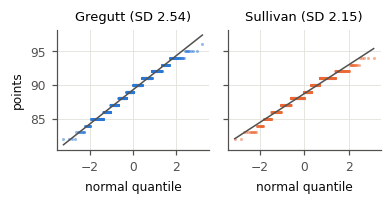

Takeaway: Both critics' scores lie close to a normal line, but Sullivan's (2.15 SD) spread less than Gregutt's (2.54 SD); the steps are whole points.
All vintages (naive): F: statistic = 1.625, df = 2,088, 2,036, p = 6.21e-28 -> reject H0; estimate = 1.6250, 95% CI [1.4905, 1.7715]


In [47]:
alt5 = chi2_variance(s, g.var(ddof=1))
show(alt5)
keep_test('fiveChi', alt5)

fig, ax = plt.subplots(1, 2, figsize=(3.6, 1.9), sharey=True)
for a, x, name, c in zip(ax, (g, s), ('Gregutt', 'Sullivan'), (BLUE, ORANGE)):
    (osm, osr), (slope_qq, icpt, _) = stats.probplot(x, dist='norm')
    a.scatter(osm, osr, s=4, color=c, alpha=0.5, linewidths=0, rasterized=True)
    a.plot(osm, slope_qq * osm + icpt, color=INK2, linewidth=1)
    a.set(title=f'{name} (SD {x.std():.2f})', xlabel='normal quantile')
ax[0].set_ylabel('points')
fig.tight_layout()
save_fig(fig, 'fig_qq')
takeaway('capQQ', f'Both critics\' scores lie close to a normal line, but Sullivan\'s ({s.std():.2f} SD) spread less '
         f'than Gregutt\'s ({g.std():.2f} SD); the steps are whole points.')

naive5 = f_test(gn, sn)
print('All vintages (naive):', end=' ')
show(naive5)
keep('fiveNaiveSDRatio', np.sqrt(naive5['est']), '{:.2f}')
SUMMARY.append(dict(test='T5', question='Gregutt vs Sullivan, spread', method='F (variances)', res=t5,
                    delta='SD ratio 1.2', verdict=v5))

**c) Result and reading.** The variances differ significantly: Gregutt spreads his scores wider. But the CI for the SD
ratio straddles 1.2, so whether the difference in spread **matters is unclear**. The data cannot tell a small
difference from one that matters. The one-variance χ² test gives a far smaller p because it treats Gregutt's variance
as known, which is exactly why it was not the main test. Ignoring vintages would have overstated the spread
difference (the naive SD ratio is larger).

### Summary of the five tests

In [48]:
def summary_row(row):
    res, sc = row['res'], row.get('scale', 1)
    est = '-' if np.isnan(res['est']) else Tex(f"{num(res['est'] * sc, 3 if sc == 1 else 1)} "
                                               f"({num(res['lo'] * sc, 3 if sc == 1 else 1)}, {num(res['hi'] * sc, 3 if sc == 1 else 1)})")
    return {'Test': row['test'], 'Question': row['question'], 'Method': row['method'],
            'Statistic (df)': Tex(f"{num(res['stat'], 2)} ({df_text(res['df'])})"), 'p': tex_p(res['p']),
            'Decision': decide(res['p']), 'Estimate (95% CI)': est, 'Matters if': row['delta'], 'Verdict': row['verdict']}


summary = pd.DataFrame([summary_row(r) for r in SUMMARY])
save_table(summary, 'tests_summary')
summary

,Test,Question,Method,Statistic (df),p,Decision,Estimate (95% CI),Matters if,Verdict
0,T1,"Old vs New World, $20-40",Welch t,"24.64 (42,033)",\ensuremath{3.8\times10^{-133}},reject H0,"0.595 (0.548, 0.643)",1 point,does not matter
1,T2,note length vs points,t on Pearson r,"213.07 (111,509)",\ensuremath{<10^{-300}},reject H0,"0.538 (0.534, 0.542)",rho = 0.3,matters
2,T3,price band x 90+,chi-square independence,"30,191.95 (4)",\ensuremath{<10^{-300}},reject H0,-,5 pp between adjacent bands,4 of 4 steps matter
3,T4,"Gregutt vs Sullivan, 90+ share",two-proportion z,4.92 (-),\ensuremath{8.8\times10^{-7}},reject H0,"11.4 (6.9, 16.0)",5 pp,matters
4,T5,"Gregutt vs Sullivan, spread",F (variances),"1.40 (1,046, 805)",\ensuremath{5.5\times10^{-7}},reject H0,"1.399 (1.227, 1.592)",SD ratio 1.2,unclear


## 6. Limitations
The numbers below feed the Limitations section of the report.

In [49]:
per_winery = winery_col.value_counts()
share80 = (df.points == 80).mean()
top_taster_share = T.taster_name.value_counts(normalize=True).drop('Unknown')
print(f'points == 80 (the floor): {share80:.2%}')
print(f'wineries with 10+ reviews hold {per_winery[per_winery >= 10].sum() / per_winery.sum():.0%} of reviews')
print(f'largest named critic share of tested rows: {top_taster_share.index[0]} {top_taster_share.iloc[0]:.0%}')
keep('pctAtEighty', 100 * share80, '{:.1f}')
keep('pctBigWinery', 100 * per_winery[per_winery >= 10].sum() / per_winery.sum(), '{:.0f}')
keep('topTaster', top_taster_share.index[0], '{}')
keep('topTasterShare', 100 * top_taster_share.iloc[0], '{:.0f}')

points == 80 (the floor): 0.33%
wineries with 10+ reviews hold 66% of reviews
largest named critic share of tested rows: Roger Voss 17%


* **Truncated response.** WineEnthusiast does not publish scores below 80, so `points` is cut at 80. Means are biased
  up and spreads down relative to all wines tasted; the tests describe published reviews only.
* **Rows are not fully independent.** Wines from one winery, and scores from one critic, share influences. The
  effective sample is smaller than *n*, so the p-values are optimistic. The practical-significance verdicts
  (interval vs threshold) carry the argument for that reason.
* **Association, not cause.** Longer notes do not *cause* high scores (critics write more about wines they like).
  Old vs New World is confounded with the critic (T1). Gregutt vs Sullivan could still differ in which wineries
  they were sent.
* **Imputed prices left out.** Price is missing systematically by country (2.4), so the tested rows under-represent
  those countries.
* **Narrow slices.** T1 uses $20–40 bottles, and T4/T5 use Washington $20–40 wines from the shared vintages.
  Other prices, regions and critics may behave differently.
* **Data age.** The scrape is from 2017. Critics and scoring habits may have changed since.

## 7. Export
`report/numbers.tex` defines `\val{key}`; for example, `\val{rowsClean}` prints the cleaned row count.

In [50]:
lines = [r'% Generated by notebooks/midterm.ipynb (Section 7). Do not edit by hand.',
         r'\makeatletter',
         r'\newcommand{\val}[1]{\ifcsname val@#1\endcsname\csname val@#1\endcsname\else\textbf{??#1??}\fi}']
lines += [rf'\expandafter\def\csname val@{k}\endcsname{{{v}}}' for k, v in sorted(NUM.items())]
lines += [r'\makeatother']
(ROOT / 'report' / 'numbers.tex').write_text('\n'.join(lines) + '\n', encoding='utf-8')

results = {r['test']: {k: (list(v) if isinstance(v, tuple) else (None if v is None else float(v)))
                       for k, v in r['res'].items() if k != 'test'} | {'method': r['method'], 'verdict': r['verdict']}
           for r in SUMMARY}
(ROOT / 'report' / 'results.json').write_text(json.dumps(results, indent=2), encoding='utf-8')

print(f'{len(NUM)} values -> report/numbers.tex')
print('tables :', sorted(p.name for p in TAB.glob('*.tex')))
print('figures:', sorted(p.name for p in FIG.glob('*.pdf')))

231 values -> report/numbers.tex
tables : ['before_after.tex', 'features.tex', 'prep.tex', 'step_log.tex', 't2_tasters.tex', 't3_bands.tex', 'tests_summary.tex']
figures: ['fig_band90.pdf', 'fig_points.pdf', 'fig_price_outliers.pdf', 'fig_price_points.pdf', 'fig_qq.pdf', 'fig_tasters.pdf', 'fig_wa_vintages.pdf', 'fig_words.pdf']
